# 📥 Introduction to Importing Data in Python — Showcase

> **Platform:** DataCamp · **Track:** Data Engineer in Python · **Course 4** · **Instructor:** Hugo Bowne-Anderson

Before any analysis or pipeline, data has to get **into** Python. This course covers the three main sources: flat files, files from other software, and relational databases. Every example below runs on the real course datasets in [`datasets/`](datasets/).

**Chapters**
1. Flat files: plain text, NumPy (`loadtxt`, `genfromtxt`) and pandas (`read_csv`)
2. Other file types: pickle, Excel, SAS, Stata, HDF5, MATLAB
3. Relational databases: SQLAlchemy engines, SQL queries and joins with pandas

| Dataset | Format | Used for |
|---|---|---|
| `seaslug.txt` | Tab-delimited text | Plain text reading, NumPy with headers |
| `mnist.csv` | Numeric CSV | `np.loadtxt` |
| `titanic.csv` | Mixed-type CSV | `np.genfromtxt`, `pd.read_csv` |
| `battledeath.xlsx` | Excel (2 sheets) | `pd.ExcelFile` |
| `sales.sas7bdat` | SAS | `SAS7BDAT`, `pd.read_sas` |
| `disarea.dta` | Stata | `pd.read_stata` |
| `L-L1_LOSC_4_V1-1126259446-32.hdf5` | HDF5 (LIGO) | `h5py` |
| `ja_data2.mat` | MATLAB | `scipy.io.loadmat` |
| `Chinook.sqlite` | SQLite database | SQLAlchemy + pandas |

In [1]:
import os
import pickle
import tempfile

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io

DATA = "datasets"

---
## Chapter 1 — Flat files

### 1.1 Plain text files
`open(file, mode="r")` returns a file object; `.read()` returns the whole content and `.readline()` one line at a time. A file opened manually must be closed. The **context manager** (`with`) closes it automatically, so it is the preferred way. Mode `"w"` writes (and overwrites).

In [2]:
file = open(os.path.join(DATA, "seaslug.txt"), mode="r")
text = file.read()
file.close()
print(file.closed)
print(text[:60])

True
Time	Percent
99	0.067
99	0.133
99	0.067
99	0
99	0
0	0.5
0	0.


In [3]:
with open(os.path.join(DATA, "seaslug.txt")) as file:
    print(file.readline(), end="")   # header
    print(file.readline(), end="")   # first record
    print(file.readline(), end="")

# Writing: mode "w" (temporary folder so the repo stays clean)
tmp_dir = tempfile.mkdtemp()
with open(os.path.join(tmp_dir, "note.txt"), "w") as f:
    f.write("Imported with a context manager")
with open(os.path.join(tmp_dir, "note.txt")) as f:
    print(f.read())

Time	Percent
99	0.067
99	0.133
Imported with a context manager


### 1.2 Flat files and NumPy
A **flat file** stores table data as text: each row is a **record**, each column a **field**, separated by a **delimiter** (comma, tab), often with a header. NumPy arrays are the standard for **numerical** data.

`np.loadtxt()` options: `delimiter`, `skiprows` (number of rows to skip, not an index), `usecols` (columns to keep) and `dtype`.

<class 'numpy.ndarray'> (100, 785)
First labels: [1. 0. 1. 4. 0. 0. 7. 3. 5. 3.]


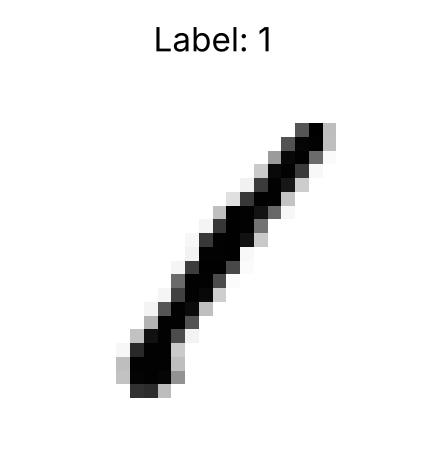

In [4]:
digits = np.loadtxt(os.path.join(DATA, "mnist.csv"), delimiter=",")
print(type(digits), digits.shape)            # 100 images: label + 784 pixels

labels = np.loadtxt(os.path.join(DATA, "mnist.csv"), delimiter=",", usecols=[0])
print("First labels:", labels[:10])

# Reshape one row's pixels into a 28x28 image
plt.figure(figsize=(2.5, 2.5))
plt.imshow(digits[0, 1:].reshape(28, 28), cmap="Greys")
plt.title(f"Label: {int(digits[0, 0])}")
plt.axis("off")
plt.show()

[['Time' 'Percent']
 ['99' '0.067']
 ['99' '0.133']]
(47, 2) float64


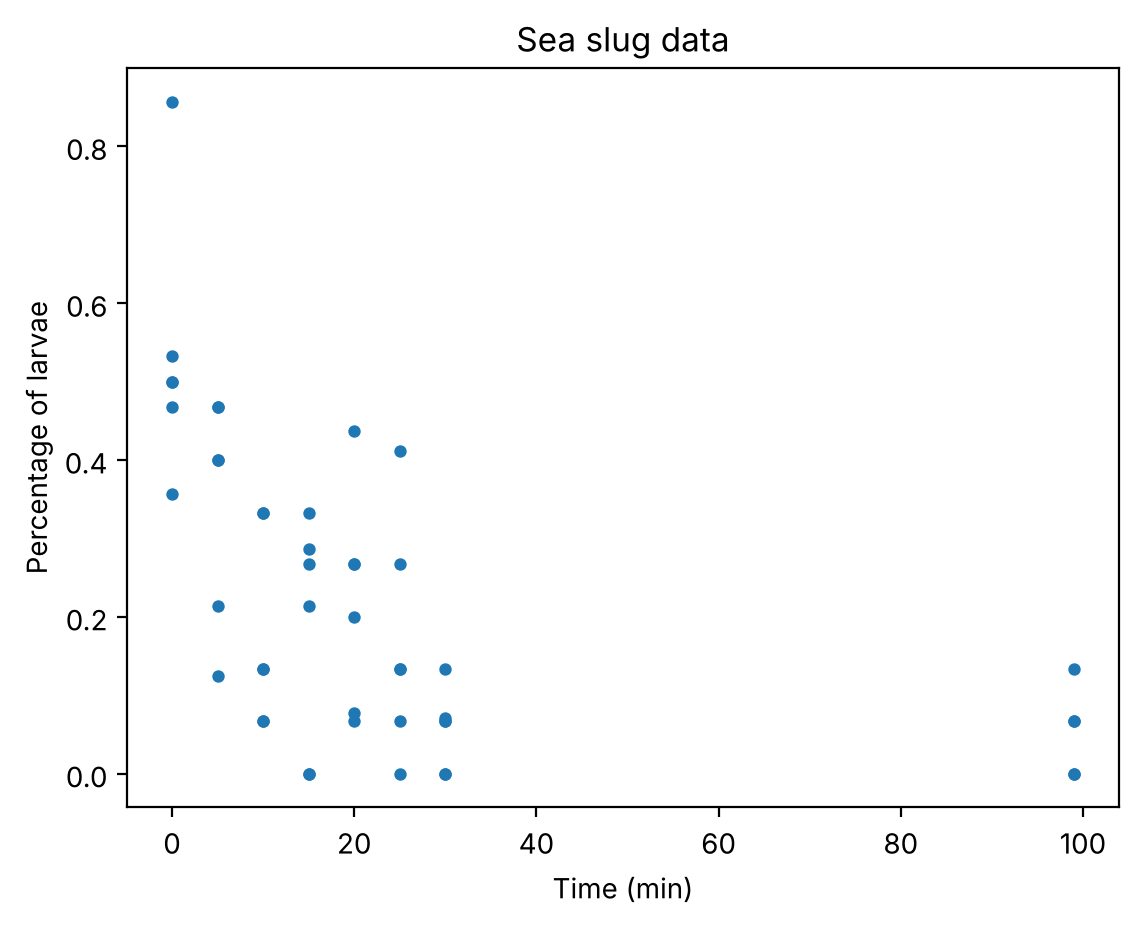

In [5]:
# A header row breaks a numeric import unless we skip it or read everything as strings
seaslug_str = np.loadtxt(os.path.join(DATA, "seaslug.txt"), delimiter="\t", dtype=str)
print(seaslug_str[:3])

seaslug = np.loadtxt(os.path.join(DATA, "seaslug.txt"), delimiter="\t", skiprows=1)
print(seaslug.shape, seaslug.dtype)

plt.scatter(seaslug[:, 0], seaslug[:, 1], s=12)
plt.xlabel("Time (min)"); plt.ylabel("Percentage of larvae"); plt.title("Sea slug data")
plt.show()

**Mixed data types.** `loadtxt` fails when columns mix strings and numbers. `np.genfromtxt(..., names=True, dtype=None)` infers a type per column and returns a **structured array** where each row is a record and columns are accessed by name.

In [6]:
titanic_np = np.genfromtxt(os.path.join(DATA, "titanic.csv"), delimiter=",",
                           names=True, dtype=None, encoding="utf-8")
print(titanic_np.dtype.names)
print(titanic_np[0])
print("Fares:", titanic_np["Fare"][:5])

('PassengerId', 'Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked')
(1, 0, 3, 'male', 22.0, 1, 0, 'A/5 21171', 7.25, '', 'S')
Fares: [ 7.25   71.2833  7.925  53.1     8.05  ]


### 1.3 Flat files and pandas
pandas `DataFrame`: two-dimensional, labeled, columns of different types, with tools for wrangling, statistics, time series and modeling. It is the standard for importing flat files. Useful `read_csv` options: `nrows`, `header=None`, `sep`, `comment` and `na_values`. `.to_numpy()` converts back to an array.

In [7]:
titanic = pd.read_csv(os.path.join(DATA, "titanic.csv"))
print(titanic.shape)
titanic.head()

(891, 11)


,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,male,35.0,0,0,373450,8.0500,NaN,S


In [8]:
# First 5 rows of mnist, no header, converted to NumPy
mnist_head = pd.read_csv(os.path.join(DATA, "mnist.csv"), nrows=5, header=None)
print(type(mnist_head.to_numpy()), mnist_head.shape)

# Tab-separated file
print(pd.read_csv(os.path.join(DATA, "seaslug.txt"), sep="\t").head(3))

<class 'numpy.ndarray'> (5, 785)
   Time  Percent
0    99    0.067
1    99    0.133
2    99    0.067


In [9]:
# Messy flat file: comments and custom missing-value markers
import io
messy = """id,city,temp
1,Medellin,24 # sensor A
2,Bogota,Nothing
3,Cali,30
"""
clean = pd.read_csv(io.StringIO(messy), comment="#", na_values=["Nothing"])
print(clean)
print("Missing values per column:", clean.isna().sum().to_dict())

   id      city  temp
0   1  Medellin  24.0
1   2    Bogota   NaN
2   3      Cali  30.0
Missing values per column: {'id': 0, 'city': 0, 'temp': 1}


---
## Chapter 2 — Other file types

### 2.1 Pickled files
Pickle is Python's native format for **serializing** objects (converting them into a byte stream) that have no obvious text representation. Files are opened in binary mode: `"wb"` to write, `"rb"` to read.

In [10]:
fruit = {"peaches": 13, "apples": 4, "oranges": 11}
pkl_path = os.path.join(tmp_dir, "pickled_fruit.pkl")

with open(pkl_path, "wb") as file:
    pickle.dump(fruit, file)
with open(pkl_path, "rb") as file:
    data = pickle.load(file)

print(data, type(data))

{'peaches': 13, 'apples': 4, 'oranges': 11} <class 'dict'>


### 2.2 Excel spreadsheets
`pd.ExcelFile()` loads the workbook; `.sheet_names` lists the sheets and `.parse()` reads one by **name** (string) or **index** (integer). `parse` can skip rows, pick columns and rename them.

In [11]:
xls = pd.ExcelFile(os.path.join(DATA, "battledeath.xlsx"))
print(xls.sheet_names)

df_2002 = xls.parse("2002")    # by name
df_2004 = xls.parse(1)         # by index
print(df_2002.head(3))

['2002', '2004']
  War, age-adjusted mortality due to       2002
0                        Afghanistan  36.083990
1                            Albania   0.128908
2                            Algeria  18.314120


In [12]:
# Customize: rename columns
df_custom = xls.parse(0, names=["Country", "AAM due to War (2002)"])
print(df_custom.head(3))

# Skip the original header row, keep only the first column and name it ourselves
# (header=None prevents the first data row from being used as the header)
countries_2004 = xls.parse(1, skiprows=[0], usecols=[0], header=None, names=["Country"])
print(countries_2004.head(3))

       Country  AAM due to War (2002)
0  Afghanistan              36.083990
1      Albania               0.128908
2      Algeria              18.314120
       Country
0  Afghanistan
1      Albania
2      Algeria


### 2.3 SAS and Stata files
- **SAS** (Statistical Analysis System) is common in business analytics and biostatistics: `.sas7bdat` files.
- **Stata** ("statistics" + "data") is common in academic social science research: `.dta` files.

SAS files can be read with the `sas7bdat` package (as in the course) or directly with `pd.read_sas`. Stata files use `pd.read_stata`.

     YEAR     P           S
0  1950.0  12.9  181.899994
1  1951.0  11.9  245.000000
2  1952.0  10.7  250.199997
3  1953.0  11.3  265.899994
4  1954.0  11.2  248.500000
(36, 3)


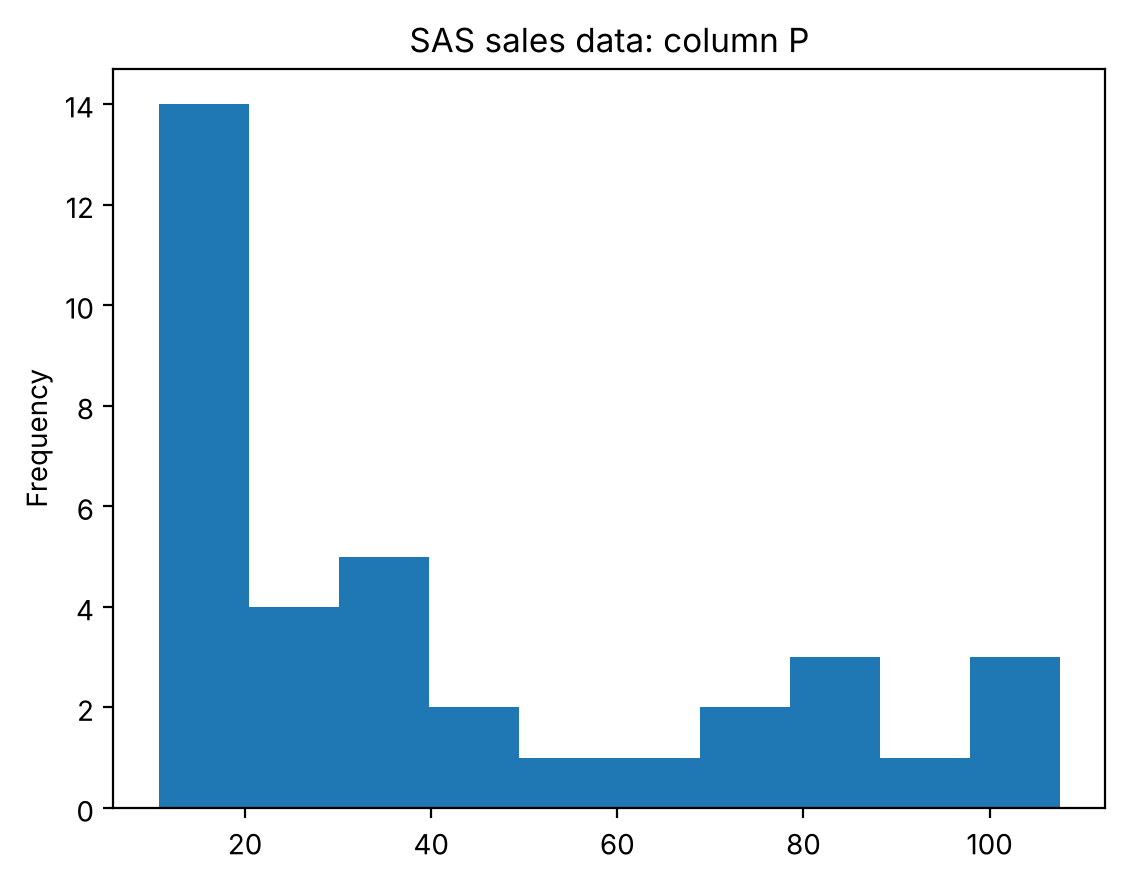

In [13]:
from sas7bdat import SAS7BDAT

with SAS7BDAT(os.path.join(DATA, "sales.sas7bdat")) as file:
    df_sas = file.to_data_frame()
print(df_sas.head())

print(pd.read_sas(os.path.join(DATA, "sales.sas7bdat")).shape)   # pandas alternative

df_sas["P"].plot(kind="hist", title="SAS sales data: column P")
plt.show()

In [14]:
df_stata = pd.read_stata(os.path.join(DATA, "disarea.dta"))
print(df_stata.shape)
print(df_stata[["wbcode", "country", "disa10"]].head())

(164, 27)
  wbcode               country  disa10
0    AFG           Afghanistan    0.00
1    AGO                Angola    0.13
2    ALB               Albania    0.00
3    ARE  United Arab Emirates    0.00
4    ARG             Argentina    0.00


### 2.4 HDF5 files
**HDF5** (Hierarchical Data Format v5) is a standard for very large numerical datasets (it can scale to exabytes). `h5py.File(path, "r")` opens it, and its structure works like nested dictionaries: **groups** contain other groups or **datasets**. This file holds LIGO gravitational-wave detector data.

In [15]:
ligo = h5py.File(os.path.join(DATA, "L-L1_LOSC_4_V1-1126259446-32.hdf5"), "r")
print(type(ligo))

for key in ligo.keys():
    print(key, "->", type(ligo[key]).__name__)

print(list(ligo["meta"].keys()))
print(ligo["meta"]["Description"][()], ligo["meta"]["Detector"][()])

<class 'h5py._hl.files.File'>
meta -> Group
quality -> Group
strain -> Group
['Description', 'DescriptionURL', 'Detector', 'Duration', 'GPSstart', 'Observatory', 'Type', 'UTCstart']
b'Strain data time series from LIGO' b'L1'


(131072,)


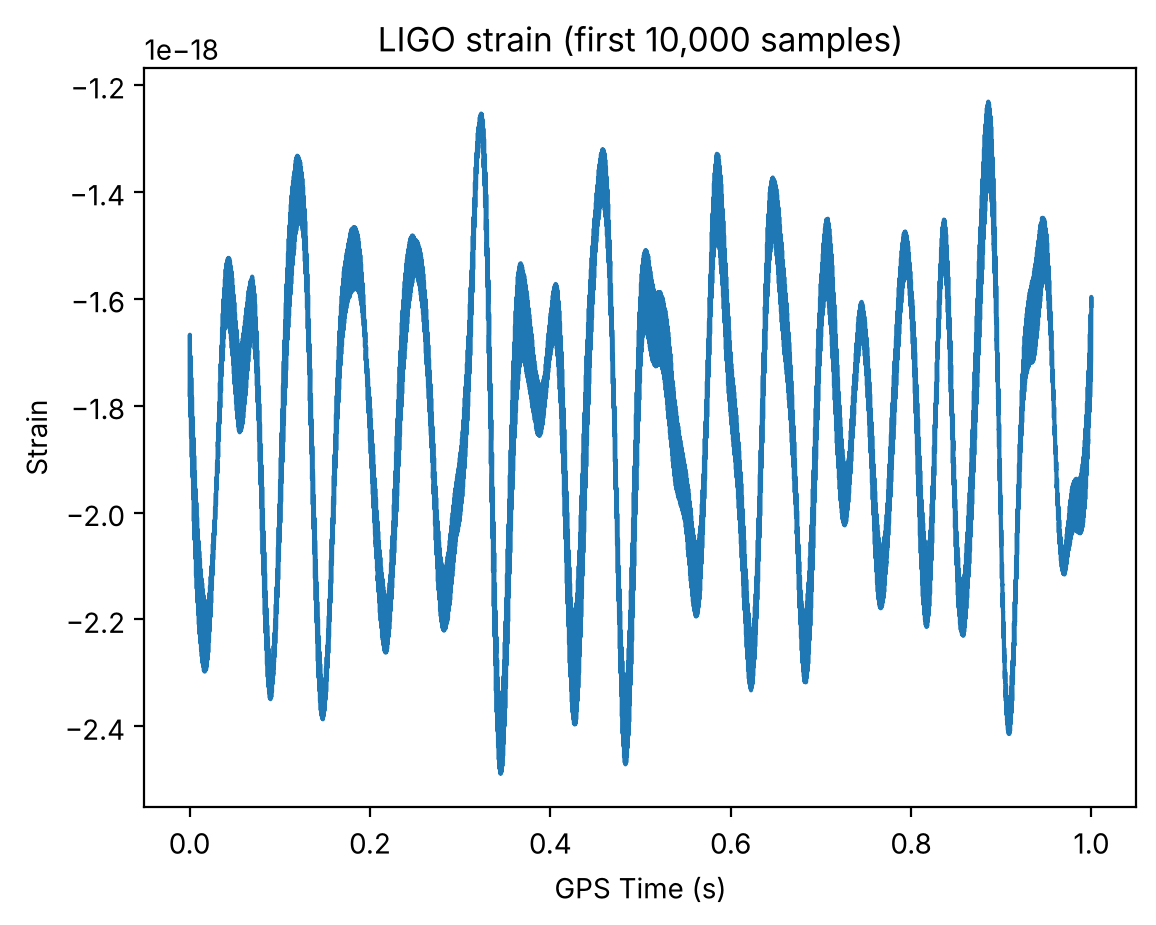

In [16]:
strain = ligo["strain"]["Strain"][()]      # dataset -> NumPy array
print(strain.shape)

num_samples = 10000
time = np.arange(0, 1, 1 / num_samples)
plt.plot(time, strain[:num_samples])
plt.xlabel("GPS Time (s)"); plt.ylabel("Strain"); plt.title("LIGO strain (first 10,000 samples)")
plt.show()
ligo.close()

### 2.5 MATLAB files
MATLAB ("Matrix Laboratory") is an engineering and science standard; its workspace is saved as `.mat`. `scipy.io.loadmat()` reads it into a **dictionary**: keys are MATLAB variable names and values are NumPy arrays (`savemat()` writes).

<class 'dict'>
['rfpCyt', 'rfpNuc', 'cfpNuc', 'cfpCyt', 'yfpNuc', 'yfpCyt', 'CYratioCyt']
<class 'numpy.ndarray'> (200, 137)


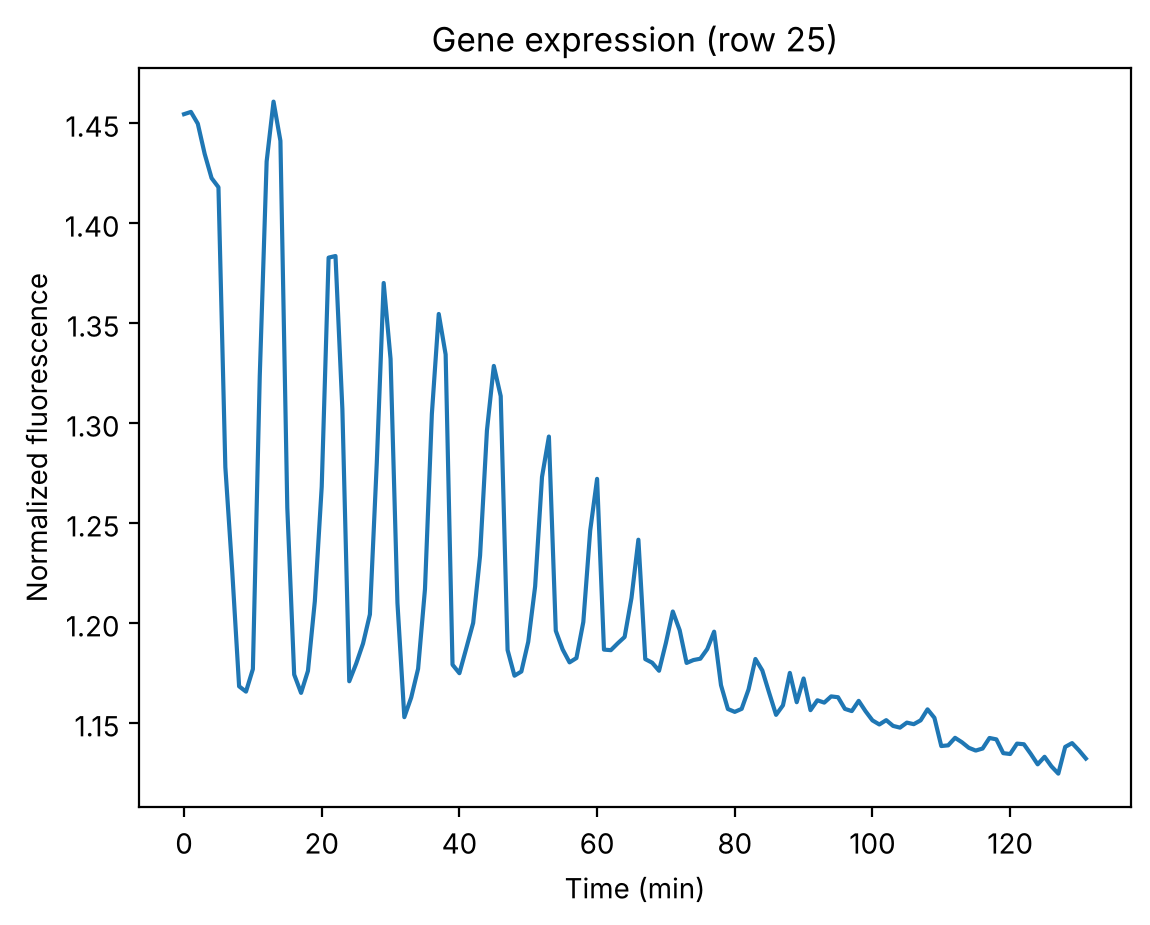

In [17]:
mat = scipy.io.loadmat(os.path.join(DATA, "ja_data2.mat"))
print(type(mat))
print([k for k in mat.keys() if not k.startswith("__")])

cfp = mat["CYratioCyt"]
print(type(cfp), cfp.shape)

plt.plot(cfp[25, 5:])
plt.xlabel("Time (min)"); plt.ylabel("Normalized fluorescence"); plt.title("Gene expression (row 25)")
plt.show()

---
## Chapter 3 — Relational databases

### 3.1 Relational model and database engines
A relational database (based on Edgar Codd's relational model) stores data in **tables** linked by **keys** (a primary key uniquely identifies each row). Examples of RDBMS: PostgreSQL, MySQL, SQLite.

**SQLAlchemy** works with many RDBMS. `create_engine()` creates the engine that manages connections. Here we use the **Chinook** SQLite database (a digital music store).

> Note: the course slides use `engine.table_names()` and `con.execute("SELECT ...")`, which were removed in SQLAlchemy 2.x. The code below uses the current API: `inspect(engine).get_table_names()` and `text()` for raw SQL.

In [18]:
from sqlalchemy import create_engine, inspect, text

engine = create_engine(f"sqlite:///{DATA}/Chinook.sqlite")
print(inspect(engine).get_table_names())

['Album', 'Artist', 'Customer', 'Employee', 'Genre', 'Invoice', 'InvoiceLine', 'MediaType', 'Playlist', 'PlaylistTrack', 'Track']


### 3.2 Querying with SQLAlchemy
Workflow: create the engine → connect → execute the query → save results to a DataFrame → set column names → close the connection. The context manager closes the connection for us. `fetchall()` returns all rows and `fetchmany(size=n)` only `n`.

In [19]:
con = engine.connect()
rs = con.execute(text("SELECT * FROM Album"))
df_album = pd.DataFrame(rs.fetchall())
df_album.columns = rs.keys()
con.close()
print(df_album.shape)
df_album.head()

(347, 3)


,AlbumId,Title,ArtistId
0,1,For Those About To Rock We Salute You,1
1,2,Balls to the Wall,2
2,3,Restless and Wild,2
3,4,Let There Be Rock,1
4,5,Big Ones,3


In [20]:
with engine.connect() as con:
    rs = con.execute(text("SELECT LastName, Title FROM Employee"))
    df = pd.DataFrame(rs.fetchmany(size=3))
    df.columns = rs.keys()
print(df)

  LastName                Title
0    Adams      General Manager
1  Edwards        Sales Manager
2  Peacock  Sales Support Agent


In [21]:
# Filter with WHERE and sort with ORDER BY
with engine.connect() as con:
    rs = con.execute(text("SELECT * FROM Employee WHERE EmployeeId >= 6 ORDER BY BirthDate"))
    df = pd.DataFrame(rs.fetchall(), columns=rs.keys())
df[["EmployeeId", "LastName", "Title", "BirthDate"]]

,EmployeeId,LastName,Title,BirthDate
0,8,Callahan,IT Staff,1968-01-09 00:00:00
1,7,King,IT Staff,1970-05-29 00:00:00
2,6,Mitchell,IT Manager,1973-07-01 00:00:00


### 3.3 The pandas way
`pd.read_sql_query(query, engine)` does the whole workflow in one line and returns a DataFrame with column names already set.

In [22]:
df_pandas = pd.read_sql_query("SELECT * FROM Album", engine)
print("Same result as the manual workflow:", df_pandas.equals(df_album))
print(df_pandas.shape)

query = "SELECT * FROM Employee WHERE EmployeeId >= 6 ORDER BY BirthDate"
pd.read_sql_query(query, engine)[["EmployeeId", "LastName", "BirthDate"]]

Same result as the manual workflow: True
(347, 3)


,EmployeeId,LastName,BirthDate
0,8,Callahan,1968-01-09 00:00:00
1,7,King,1970-05-29 00:00:00
2,6,Mitchell,1973-07-01 00:00:00


### 3.4 Exploiting table relationships: INNER JOIN
Because tables are linked by keys, a `JOIN` combines them in one query, for example album titles with their artist names.

In [23]:
albums_artists = pd.read_sql_query(
    """
    SELECT Title, Name
    FROM Album
    INNER JOIN Artist ON Album.ArtistId = Artist.ArtistId
    """,
    engine,
)
albums_artists.head()

,Title,Name
0,For Those About To Rock We Salute You,AC/DC
1,Balls to the Wall,Accept
2,Restless and Wild,Accept
3,Let There Be Rock,AC/DC
4,Big Ones,Aerosmith


In [24]:
# JOIN + WHERE: short tracks that appear in playlists
short_tracks = pd.read_sql_query(
    """
    SELECT PlaylistTrack.PlaylistId, Track.Name, Track.Milliseconds
    FROM PlaylistTrack
    INNER JOIN Track ON PlaylistTrack.TrackId = Track.TrackId
    WHERE Track.Milliseconds < 250000
    """,
    engine,
)
print(short_tracks.shape)
short_tracks.head()

(4073, 3)


,PlaylistId,Name,Milliseconds
0,1,One and the Same,217732
1,1,Until We Fall,230758
2,1,Original Fire,218916
3,1,Broken City,228366
4,1,Somedays,213831


## 🎯 Key takeaways

- **Flat files:** NumPy for purely numerical data (`loadtxt`, `genfromtxt` for mixed types); pandas `read_csv` as the default, with options for headers, delimiters, comments and missing values.
- **Other formats:** each has its tool (pickle, `ExcelFile`, `read_sas`/`read_stata`, `h5py`, `scipy.io.loadmat`), and most end as a DataFrame or NumPy array.
- **Databases:** SQLAlchemy engine + SQL (`SELECT`, `WHERE`, `ORDER BY`, `JOIN`), or `pd.read_sql_query` in one line.
- Always release resources: context managers for files and connections.

**In a Data Analyst / Data Engineer role:** this is the **Extract** step of ETL. Real pipelines ingest heterogeneous sources (CSV exports, Excel reports from business teams, legacy SAS/Stata files, scientific HDF5 data, production databases) and normalize them into DataFrames before transforming and loading them into a warehouse.